In [1]:
# Check that GPU is used
import tensorflow as tf
tf.config.list_physical_devices('GPU')

[]

In [2]:
from PIL import Image
import os
import numpy as np

# Define the folders where your data is stored
train_folder = 'chest_xray/train'
test_folder = 'chest_xray/test'
val_folder = 'chest_xray/val'

# Define the subfolders within each folder where the images are stored
subfolders = ['NORMAL', 'VIRUS', 'BACTERIA']

# Define the size of the images you want to resize your images to
img_width, img_height = 224, 224

In [3]:
def split_virus_bacteria_pneumonia(folder):
    temp_subfolders = ['NORMAL', 'VIRUS', 'BACTERIA']

    # Create the subfolders if they don't exist
    for subfolder in subfolders:
        if not os.path.exists(os.path.join(folder, subfolder)):
            os.makedirs(os.path.join(folder, subfolder))

    # Move the images to the corresponding subfolder
    for subfolder in temp_subfolders:
        subfolder_path = os.path.join(folder, subfolder)
        if subfolder == 'PNEUMONIA':
            for filename in os.listdir(subfolder_path):
                if 'virus' in filename:
                    os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, 'VIRUS', filename))
                elif 'bacteria' in filename:
                    os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, 'BACTERIA', filename))
        else:
            for filename in os.listdir(subfolder_path):
                os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, subfolder, filename))

In [4]:
# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(train_folder)

# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(test_folder)

# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(val_folder)

In [5]:
# Function to load and resize images from a folder
def load_images_from_folder(folder, limit_per_subfolder=None):
    X = []
    y = []
    for subfolder in subfolders:
        folder_path = os.path.join(folder, subfolder)
        if limit_per_subfolder:
            # Get amount of random filenames from the folder
            filenames = np.random.choice(os.listdir(folder_path), limit_per_subfolder, replace=False)
        else:
            filenames = os.listdir(folder_path)
        for filename in filenames:
            img_path = os.path.join(folder_path, filename)
            img = Image.open(img_path)

            # Resize the image to the desired size
            img = img.resize((img_width, img_height))

            img = img.convert('RGB')

            # Convert the image to a NumPy array and append it to X
            img = np.array(img)
            X.append(img)

            # Append the corresponding label to y
            y.append(subfolders.index(subfolder))

    X = np.array(X)
    y = np.array(y)
    return X, y

In [6]:
# Generate augmented for the training set
from data_augmentation import generate_augmented_images
generate_augmented_images(train_folder, 'NORMAL', image_size=(img_width, img_height))
generate_augmented_images(train_folder, 'BACTERIA', image_size=(img_width, img_height))
generate_augmented_images(train_folder, 'VIRUS', image_size=(img_width, img_height))

Found 1341 images belonging to 1 classes.
Additional count of images to generate: 0
Given NORMAL count: 1341
Augmented NORMAL count: 5000
Found 2530 images belonging to 1 classes.
Additional count of images to generate: 0
Given BACTERIA count: 2530
Augmented BACTERIA count: 5000
Found 1345 images belonging to 1 classes.
Additional count of images to generate: 0
Given VIRUS count: 1345
Augmented VIRUS count: 5000


In [7]:
# Load the training data
# Get min value between the number of normal images and the number of pneumonia images
train_folder = train_folder if train_folder.endswith('_augmented') else f"{train_folder}_augmented"
min_images = min(len(os.listdir(os.path.join(train_folder, subfolders[0]))), len(os.listdir(os.path.join(train_folder, subfolders[1]))), len(os.listdir(os.path.join(train_folder, subfolders[2]))))
X_train, y_train = load_images_from_folder(train_folder, min_images)

# Load the test data
X_test, y_test = load_images_from_folder(test_folder)

# Load the validation data
X_val, y_val = load_images_from_folder(val_folder)

In [8]:
# One-hot encode the labels
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
y_val = to_categorical(y_val)

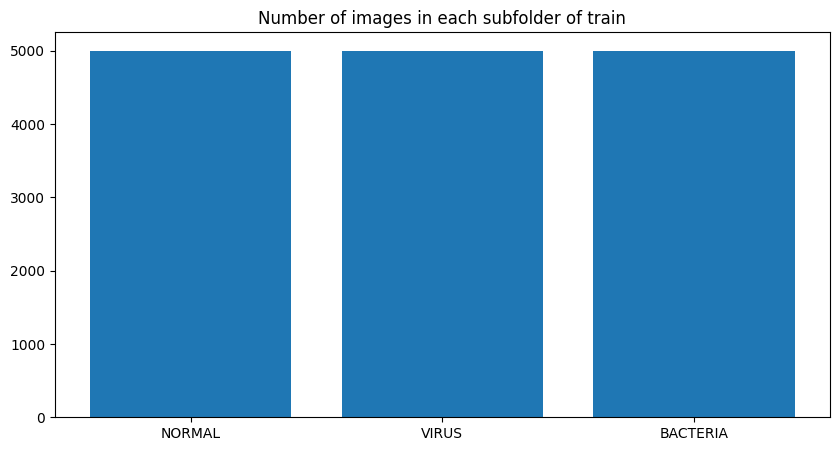

In [9]:
# Make a matplot figure to show how many images are in each subfolder of train
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.bar(subfolders, [len(os.listdir(os.path.join(train_folder, subfolder))) for subfolder in subfolders])
plt.title('Number of images in each subfolder of train')
plt.show()

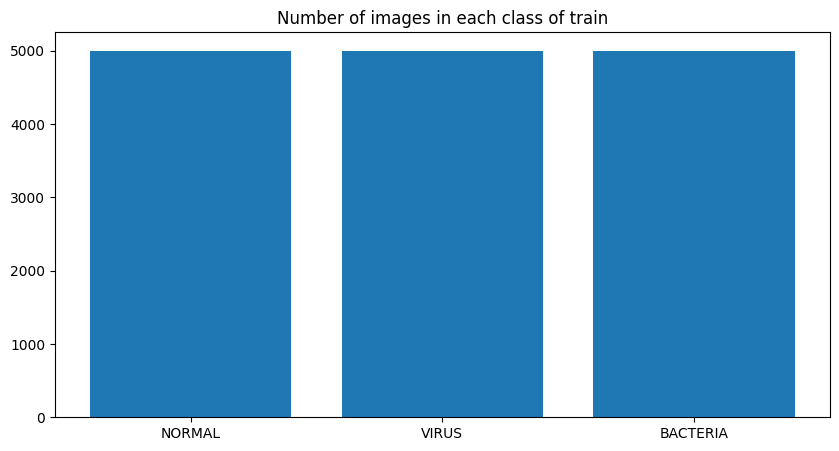

In [10]:
# Make a matplot figure to show how many images if each class in the training set considering it is hot-encoded
plt.figure(figsize=(10, 5))
plt.bar(subfolders, [sum(y_train[:, i]) for i in range(len(subfolders))])
plt.title('Number of images in each class of train')
plt.show()

In [11]:
# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255
X_val = X_val.astype('float32') / 255

X_train = X_train.reshape(len(X_train), img_width, img_height, 3)
X_test = X_test.reshape(len(X_test), img_width, img_height, 3)
X_val = X_val.reshape(len(X_val), img_width, img_height, 3)

(224, 224, 3)


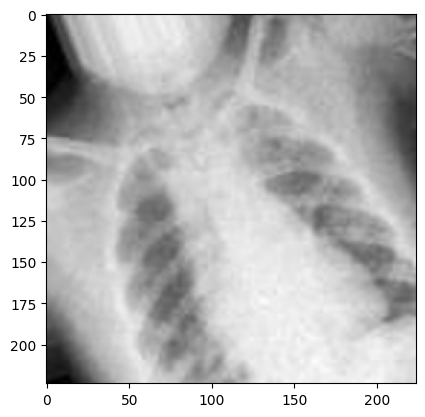

In [12]:
single_image = X_train[np.random.randint(len(X_train))]
print(single_image.shape)
plt.imshow(single_image, cmap='Greys')

In [ ]:
# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255
X_val = X_val.astype('float32') / 255

X_train = X_train.reshape(len(X_train), img_width, img_height, 3)
X_test = X_test.reshape(len(X_test), img_width, img_height, 3)
X_val = X_val.reshape(len(X_val), img_width, img_height, 3)

In [ ]:
single_image = X_train[np.random.randint(len(X_train))]
print(single_image.shape)
plt.imshow(single_image, cmap='Greys')

In [ ]:
# Define model metrics
from keras.metrics import AUC

metrics = [
    "accuracy",
    AUC(name='auc')
]

In [ ]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

def create_model():
    base_model = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_shape=(img_width, img_height, 3)
    )

    base_model.trainable = False

    model = Sequential()
    model.add(base_model)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(3, activation='softmax'))

    model.compile(loss="categorical_crossentropy", optimizer=Adam(), metrics=metrics)

    return model


In [ ]:
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Cross-validation parameters
n_splits = 5
epochs_head = 7         
epochs_finetune = 5     
batch_size = 32
fine_tune_at = 400   

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)

# Résultats
accuracy_scores = []
histories = []
models = []

# Générateur d'images
datagen = ImageDataGenerator()

# KFold
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train, y_train)):
    print(f"\n🔁 Fold {fold+1}/{n_splits}")

    # Split des données
    X_train_fold, y_train_fold = X_train[train_idx], y_train[train_idx]
    X_val_fold, y_val_fold = X_train[val_idx], y_train[val_idx]

    train_generator = datagen.flow(X_train_fold, y_train_fold, batch_size=batch_size)
    val_generator = datagen.flow(X_val_fold, y_val_fold, batch_size=batch_size)

    # Modèle
    model = create_model() 

    print("Entraînement de la tête (DenseNet gelé)")
    model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=epochs_head,
        callbacks=[early_stop],
        verbose=1
    )

    print("Fine-tuning des dernières couches de DenseNet")
    base_model = model.layers[0]
    base_model.trainable = True
    for i, layer in enumerate(base_model.layers):
        layer.trainable = i >= fine_tune_at  

    model.compile(
        optimizer=Adam(learning_rate=1e-5),
        loss='categorical_crossentropy',
        metrics=['accuracy', 'AUC']
    )

    history_ft = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=epochs_finetune,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )

    # Fusionne les historiques (tête + fine-tuning)
    combined_history = {}
    for key in history_ft.history:
        combined_history[key] = history_ft.history[key]

    histories.append(combined_history)
    models.append(model)

    acc = model.evaluate(val_generator, verbose=0)[1]
    accuracy_scores.append(acc)
    print(f"✅ Accuracy du fold {fold+1} : {acc:.4f}")
